# Analyse OpenFold 3 model predictions for the de novo designed sequences

In [ ]:
import glob 
import os
import json
import pandas as pd
from tqdm import tqdm
import numpy as np
import sys
import matplotlib.pyplot as plt

# Custom imports from utils.py
script_dir = os.path.dirname(os.path.abspath(os.getcwd()))
repo_path = script_dir.split("WP2_Sweet_Protein_Discovery")[0] + "/WP2_Sweet_Protein_Discovery"
sys.path.append(repo_path)
from utils import cif_to_pdb_gemmi, calculate_tm_score, residues_to_check, sequence_identity

native_mnei_seq = "GEWEIIDIGPFTQNLGKFAVDEENKIGQYGRLTFNKVIRPCMKKTIYENEGFREIKGYEYQLYVYASDKLFRADISEDYKTRGRKLLRFNGPVPPP"

outdir = f"{repo_path}/7_de_novo_designs/3_tm_scores"
os.makedirs(outdir, exist_ok=True)

# Make a dataframe to store the results
data = []
for fasta in glob.glob(f"{repo_path}/7_de_novo_designs/2_of3_jsons/*.json"):
    json_data = json.load(open(fasta))
    for name in json_data["queries"].keys():
        chain = json_data["queries"][name]["chains"][0]
        for num_model in [1,2,3,4,5]:
            seq = chain["sequence"]
            name = fasta.split("/")[-1].replace(".json", "")
            data.append({"id": name, "sequence": seq, "model": num_model})

de_novo_df = pd.DataFrame(data)
de_novo_df["of3_tm_score"] = None
de_novo_df["of3_RMSD"] = None
de_novo_df["of3_tm_align_start"] = None
de_novo_df["of3_tm_align_end"] = None
de_novo_df["of3_tm_align_length"] = None
de_novo_df["of3_tm_align_seq_id"] = None
de_novo_df["of3_avg_pLDDT"] = None
de_novo_df["of3_sample_ranking_score"] = None
de_novo_df["of3_ptm"] = None   
de_novo_df["of3_has_clash"] = None
de_novo_df["of3_disorder"] = None
de_novo_df["of3_gpde"] = None
pdb_1 = f"{repo_path}/7_de_novo_designs/1_input_pdb/MNEI_1IV7.pdb"
target = "MNEI_1IV7"

# Loop over the structures
if not os.path.exists(f"{outdir}/de_novo_tm_scores.tsv"):
    for index, row in tqdm(de_novo_df.iterrows(), total=len(de_novo_df)):
        name = row["id"]
        model = row["model"]
        pdb_path = f"{repo_path}/7_de_novo_designs/2_models/{name}/{name}/seed_42/{name}_seed_42_sample_{model}_model.cif"
        json_path = f"{repo_path}/7_de_novo_designs/2_models/{name}/{name}/seed_42/{name}_seed_42_sample_{model}_confidences_aggregated.json"

        # Read the json to get confidence metrics
        with open(json_path, "r") as f:
            json_dict = json.load(f)

        # Save confidence metrics to dataframe
        de_novo_df.at[index, "of3_sample_ranking_score"] = json_dict["sample_ranking_score"]
        de_novo_df.at[index, "of3_ptm"] = json_dict["ptm"]
        de_novo_df.at[index, "of3_has_clash"] = json_dict["has_clash"]
        de_novo_df.at[index, "of3_disorder"] = json_dict["disorder"]
        de_novo_df.at[index, "of3_avg_pLDDT"] = json_dict["avg_plddt"]
        de_novo_df.at[index, "of3_gpde"] = json_dict["gpde"]

        if os.path.exists(pdb_path):
            output_file = f"{outdir}/" + target + "____" + name + "_seed_42_sample_" + str(model) + ".txt"
            tm_score, rmsd, start, end = calculate_tm_score(pdb_1, pdb_path, output_file, norm_length=1)
            de_novo_df.at[index, "of3_tm_score"] = tm_score
            de_novo_df.at[index, "of3_RMSD"] = rmsd
            de_novo_df.at[index, "of3_tm_align_start"] = start
            de_novo_df.at[index, "of3_tm_align_end"] = end
            with open(output_file, "r") as f:
                output = f.readlines()
                for line in output:
                    if line.startswith("Aligned length="):
                        aligned_length = line.split(",")[0].split("= ")[1].strip()
                        align_seq_id = line.split(",")[2].split("= ")[1].strip()
                
                        de_novo_df.at[index, "of3_tm_align_length"] = aligned_length
                        de_novo_df.at[index, "of3_tm_align_seq_id"] = align_seq_id
        else:
            print(pdb_path, " does not exist, skipping ", target)

    de_novo_df.to_csv(f"{outdir}/de_novo_tm_scores.tsv", sep="\t", index=False)
else:
    de_novo_df = pd.read_csv(f"{outdir}/de_novo_tm_scores.tsv", sep="\t")

de_novo_df["of3_has_clash"] = de_novo_df["of3_has_clash"].astype(bool)

# Filter candidates based on OpenFold 3 confidence metrics and TM-align results

In [10]:
# First filter out the models that have disordered regions, clashes, or low confidence scores
de_novo_df_filtered = de_novo_df[(de_novo_df["of3_disorder"] < 0.01) & 
                                  (de_novo_df["of3_has_clash"] == False) & 
                                  (de_novo_df["of3_avg_pLDDT"] > 70) &
                                  (de_novo_df["of3_tm_score"] > 0.9)]
de_novo_df_filtered = de_novo_df_filtered[de_novo_df_filtered["of3_tm_align_length"] == 96]
ids_with_5_models = de_novo_df_filtered.groupby("id").filter(lambda x: len(x) == 5)["id"].unique()
de_novo_df_filtered = de_novo_df_filtered[de_novo_df_filtered["id"].isin(ids_with_5_models)]

de_novo_df_filtered["of3_seq_id"] = de_novo_df_filtered.apply(lambda row: sequence_identity(row["sequence"], native_mnei_seq), axis=1)

# For each prediction, get the structure with highest of3_sample_ranking_score and save the corresponding PDB file to a new directory
best_models_dir = f"{repo_path}/7_de_novo_designs/3_selected_designs"
os.makedirs(best_models_dir, exist_ok=True)
for id in de_novo_df_filtered["id"].unique():
    best_model = de_novo_df_filtered[de_novo_df_filtered["id"] == id].sort_values("of3_sample_ranking_score", ascending=False).iloc[0]
    model_num = best_model["model"]
    pdb_path = f"{repo_path}/7_de_novo_designs/2_models/{id}/{id}/seed_42/{id}_seed_42_sample_{model_num}_model.cif"
    output_pdb_path = f"{best_models_dir}/{id}.pdb"
    if not os.path.exists(output_pdb_path):
        print(pdb_path, " --> ", output_pdb_path)
        cif_to_pdb_gemmi(pdb_path, output_pdb_path)

de_novo_df_filtered

,id,sequence,model,of3_tm_score,of3_RMSD,of3_tm_align_start,of3_tm_align_end,of3_tm_align_length,of3_tm_align_seq_id,of3_avg_pLDDT,of3_sample_ranking_score,of3_ptm,of3_has_clash,of3_disorder,of3_gpde,of3_seq_id
5,free_03_MNEI_1IV7_10,EYKEIVPVDEYTEELGRFAVEEVNKEGKFGKLTFDKVISPVIKTTI...,1,0.98264,0.48,0,95,96,0.542,84.783897,0.154202,0.771009,False,0.0,0.636647,0.541667
6,free_03_MNEI_1IV7_10,EYKEIVPVDEYTEELGRFAVEEVNKEGKFGKLTFDKVISPVIKTTI...,2,0.98713,0.41,0,95,96,0.542,84.649071,0.154388,0.771941,False,0.0,0.640785,0.541667
7,free_03_MNEI_1IV7_10,EYKEIVPVDEYTEELGRFAVEEVNKEGKFGKLTFDKVISPVIKTTI...,3,0.98461,0.45,0,95,96,0.542,84.787125,0.154633,0.773163,False,0.0,0.637116,0.541667
8,free_03_MNEI_1IV7_10,EYKEIVPVDEYTEELGRFAVEEVNKEGKFGKLTFDKVISPVIKTTI...,4,0.98173,0.50,0,95,96,0.542,85.292114,0.156225,0.781123,False,0.0,0.619854,0.541667
9,free_03_MNEI_1IV7_10,EYKEIVPVDEYTEELGRFAVEEVNKEGKFGKLTFDKVISPVIKTTI...,5,0.97780,0.55,0,95,96,0.542,85.262695,0.155647,0.778235,False,0.0,0.622408,0.541667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,fixed_03_MNEI_1IV7_18,METEIIPIGPFTEELGRFAVEEENKRGQFGKLTFDKVLEPCIKHTI...,1,0.98080,0.51,0,95,96,0.667,80.400475,0.145172,0.725862,False,0.0,0.701965,0.666667
996,fixed_03_MNEI_1IV7_18,METEIIPIGPFTEELGRFAVEEENKRGQFGKLTFDKVLEPCIKHTI...,2,0.96273,0.97,0,95,96,0.667,80.629463,0.146092,0.730461,False,0.0,0.697516,0.666667
997,fixed_03_MNEI_1IV7_18,METEIIPIGPFTEELGRFAVEEENKRGQFGKLTFDKVLEPCIKHTI...,3,0.98700,0.42,0,95,96,0.667,80.484032,0.145329,0.726644,False,0.0,0.702662,0.666667
998,fixed_03_MNEI_1IV7_18,METEIIPIGPFTEELGRFAVEEENKRGQFGKLTFDKVLEPCIKHTI...,4,0.95951,1.25,0,95,96,0.667,80.623871,0.146177,0.730884,False,0.0,0.693591,0.666667


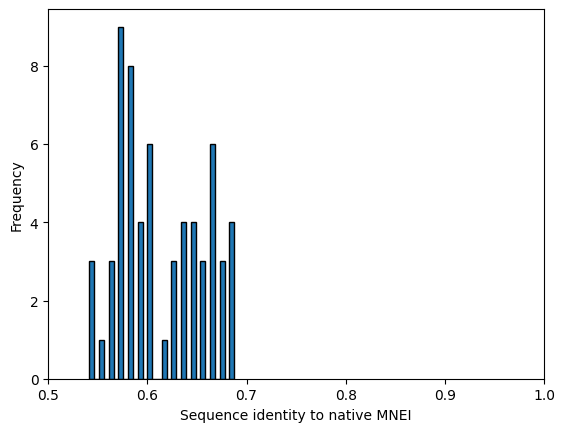

In [11]:
# Keep only one row per id (the one with highest of3_sample_ranking_score) for the histogram
de_novo_subset_df = de_novo_df_filtered.sort_values("of3_sample_ranking_score", ascending=False).groupby("id").head(1)
de_novo_subset_df["of3_seq_id"].plot(kind='hist', bins=30, edgecolor='black')
plt.xlabel('Sequence identity to native MNEI')
plt.ylabel('Frequency')
plt.xlim(0.5, 1.0)
plt.show()

# Run SurfDiff on the selected structures (these structures will be relaxed)

In [12]:
# Make surfidff json
surfdiff_dict = {}
surfdiff_dict["query-id"] = "MNEI_1IV7"
subject_ids = de_novo_df_filtered["id"].unique().tolist()
surfdiff_dict["subject-ids"] = ["cpu_relaxed_" + id for id in subject_ids]
if not os.path.exists(f"{best_models_dir}/surfdiff_input.json"):
    with open(f"{best_models_dir}/surfdiff_input.json", "w") as f:
        json.dump(surfdiff_dict, f, indent=4)

# Calculate SurfDiff similarity score at "sweet residues"

In [13]:
# Read in the SurfDiff results for all models and extract the residue similarity scores
surfdiff_res = f"{repo_path}/7_de_novo_designs/3_surfdiff_results/scores"
results = []
res_paths = glob.glob(surfdiff_res + "/*residue_uniqueness_scores.csv")
for res_file in res_paths:
    res_df = pd.read_csv(res_file, header = 0)
    model_name = os.path.basename(res_file)
    model_name = model_name.split("_cpu_relaxed_")[-1].split("_residue_uniqueness_scores.csv")[0]
    model_name = model_name.replace("_residue_uniqueness_scores.csv", "")
    if "residue_similarity_score" in res_df.columns:
        results.append([model_name, res_df["residue_similarity_score"].tolist()])

# Merge with TM-score results
results_df = pd.DataFrame(results, columns=["id", "residue_similarity_scores"])
tm_scores_df = pd.read_csv(f"{repo_path}/7_de_novo_designs/3_tm_scores/de_novo_tm_scores.tsv", sep="\t")
tm_scores_df = tm_scores_df.sort_values("of3_sample_ranking_score", ascending=False).drop_duplicates("id")
results_df = results_df.merge(tm_scores_df, on="id")

# Calculate the average similarity score for all residues for each model
results_df["avg_surfdiff_similarity"] = results_df["residue_similarity_scores"].apply(np.mean)

# Calculate the average similarity score for the important residues for each model
for index, row in results_df.iterrows():
    important_residues = residues_to_check["MNEI_1IV7"]
    important_residues = [i[1] for i in important_residues]
    if row["residue_similarity_scores"] is np.nan:
        results_df.loc[index, "avg_sweet_res_similarity"] = np.nan
        continue
    important_res_scores = [row["residue_similarity_scores"][i] for i in important_residues]
    results_df.loc[index, "avg_sweet_res_similarity"] = np.mean(important_res_scores)

# Sort by average similarity score for important residues and save to a new tsv file
results_df.sort_values(by=["avg_sweet_res_similarity"], ascending = [False], inplace = True)
results_df["cysteine_count"] = results_df["sequence"].apply(lambda x: x.count("C"))
results_df.to_csv(f"{repo_path}/8_protein_selection/0_de_novo_candidates.tsv", sep="\t", index=False)